## Cellpose-SAM: superhuman generalization for cellular segmentation

> [paper](https://www.biorxiv.org/content/10.1101/2025.04.28.651001v1) | [code](https://github.com/MouseLand/cellpose)


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

### Init


In [2]:
# !uv pip install git+https://www.github.com/mouseland/cellpose.git
# !uv pip install git+https://github.com/facebookresearch/dinov3.git

In [3]:
import os
import sys
import zarr
import glob
import json
import warnings
import numpy as np
import polars as pl
import pandas as pd
import tracksdata as td
import matplotlib.pyplot as plt

from scipy import ndimage
from pathlib import Path
from tqdm import tqdm

sys.path.insert(0, '../src')

from cellpose import models, core, io, plot


warnings.filterwarnings("ignore", category=UserWarning)

In [4]:
from params import *
from data.preparation import load_gt
from utils.plot import *
from utils.metrics import *
from utils.stitching import stitch3D, merge_close_cells, merge_close_cells_v2

## Segmentation

### Model

Here are some of the parameters you can change:

* ***flow_threshold*** is  the  maximum  allowed  error  of  the  flows  for  each  mask.   The  default  is 0.4.
    *  **Increase** this threshold if cellpose is not returning as many masks as you’d expect (or turn off completely with 0.0)
    *   **Decrease** this threshold if cellpose is returning too many ill-shaped masks.

* ***cellprob_threshold*** determines proability that a detected object is a cell.   The  default  is 0.0.
    *   **Decrease** this threshold if cellpose is not returning as many masks as you’d expect or if masks are too small
    *   **Increase** this threshold if cellpose is returning too many masks esp from dull/dim areas.

* ***tile_norm_blocksize*** determines the size of blocks used for normalizing the image. The default is 0, which means the entire image is normalized together.
  You may want to change this to 100-200 pixels if you have very inhomogeneous brightness across your image.

In [5]:
!mkdir -p ~/.cellpose/models/
!cp -r ../weights/* ~/.cellpose/models/

In [6]:
model = models.CellposeModel(gpu=core.use_gpu())
print('GPU enabled:', core.use_gpu())

GPU enabled: True


In [7]:
flow_threshold = 1
cellprob_threshold = -1
tile_norm_blocksize = 0

### Sample

In [38]:
sample_name = "44b6_0db75fae"

frame = 12

img = np.load(IMG_FOLDER + f"{sample_name}_{frame}.npy")
img = img[..., None]

# img = img[:10]

print(f'your image has shape: {img.shape}. Assuming channel dimension is last with {img.shape[-1]} channels')

your image has shape: (64, 256, 256, 1). Assuming channel dimension is last with 1 channels


In [39]:
nodes = pd.read_csv(NODES_FOLDER + f"{sample_name}.csv")
gt = nodes[nodes["t"] == frame][["z", "y", "x"]].values

In [40]:
img = img.astype(np.float32)
img = np.clip(img, np.percentile(img, 1), np.percentile(img, 99))
img = (img - img.min()) / (img.max() - img.min())

# for z in range(img.shape[0]):    
#     img[z] = np.clip(img[z], np.percentile(img[z], 1), np.percentile(img[z], 99))
#     img[z] = (img[z] - img[z].min()) / (img[z].max() - img[z].min())

img = np.clip(img, 0, 1)
img = img * 255
img = img.astype(np.uint8)


In [45]:
%%time
masks, flows, styles = model.eval(
    img,
    batch_size=64,
    flow_threshold=flow_threshold,
    cellprob_threshold=cellprob_threshold,
    # normalize=False,  # {"tile_norm_blocksize": tile_norm_blocksize},
    # min_size=1,
    # resample=False,
)


CPU times: user 5.24 s, sys: 139 ms, total: 5.37 s
Wall time: 3.58 s


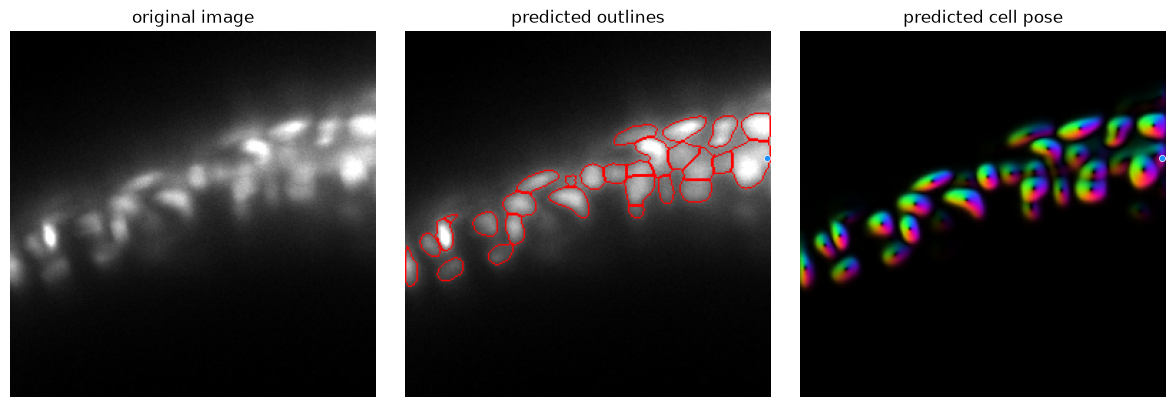

: 

In [ ]:
for i in np.unique(gt[:, 0]):
    plt.figure(figsize=(12, 4))
    show_cellpose_segmentation(img[i], masks[i], flows[0][i], nodes=gt[gt[:, 0] == i])
    plt.tight_layout()
    plt.show()

    # if i > 0:
    #     break
    break

### Custom stitching

In [18]:
MIN_SIZE = 200
STITCH_THRESHOLD = 0.6
MAX_DIST = 7

In [19]:
masks_3d = stitch3D(masks, stitch_threshold=STITCH_THRESHOLD)

ids = np.unique(masks_3d)
ids = ids[ids > 0]
seeds = ndimage.center_of_mass(masks_3d > 0, masks_3d, ids)
seeds = np.round(np.asarray(seeds))

print('Found', len(seeds), 'cells')

Found 711 cells


In [20]:
masks_3d, seeds = merge_close_cells_v2(masks_3d, seeds, max_dist=MAX_DIST)

print('Found', len(seeds), 'cells')

Found 270 cells


In [21]:
pairs, matched_gt, unmatched_gt = match_frame_nodes(
    seeds,
    gt,
    t=frame,
    scale=SCALE,
    max_distance=7,
)

print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

-> Matched 2 out of 2 GT nodes


In [22]:
for i in range(1, masks_3d.max()):
    sz  = np.sum(masks_3d == i)
    if sz < MIN_SIZE:
        masks_3d[masks_3d == i] = 0

ids = np.unique(masks_3d)
ids = ids[ids > 0]
seeds = ndimage.center_of_mass(masks_3d > 0, masks_3d, ids)
seeds = np.round(np.asarray(seeds))

print('Found', len(seeds), 'cells')


Found 228 cells


In [23]:
pairs, matched_gt, unmatched_gt = match_frame_nodes(
    seeds,
    gt,
    t=frame,
    scale=SCALE,
    max_distance=7,
)

print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

-> Matched 2 out of 2 GT nodes


/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/cellpose/utils.py:203: RuntimeWarning: invalid value encountered in cast
  slices = find_objects(masks.astype(int))


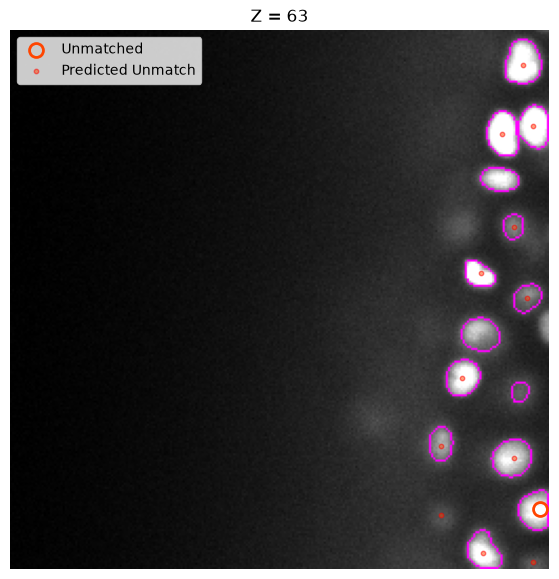

In [19]:
mask = np.where(masks_3d > 0, masks_3d, np.nan)
tol = 3

ids = np.unique(unmatched_gt[:, 0]) if len(unmatched_gt) > 0 else [2]
# ids = np.unique(gt[:, 0])

for i in ids:    
    plt.figure(figsize=(7, 7))
    plt.title(f"Z = {i}")
    plot_contours(img[i], mask[i])
    # break
    scatter_plot_center_preds(seeds, matched_gt, unmatched_gt, frame=i, tol=tol)
    plt.show()

    # break

In [20]:
# interactive_center_preds(
#     img,
#     seeds,
#     matched_gt,
#     unmatched_gt,
#     mask=masks,
#     tol=tol,
#     figsize=(6, 6),
# )

### Loop

In [25]:
df = pd.read_csv(INPUT_FOLDER + f"metadata.csv")

In [26]:
sample_name = "44b6_0db75fae"


nodes = pd.read_csv(NODES_FOLDER + f"{sample_name}.csv")

In [28]:
PLOT = True
VERBOSE = False

  7%|▋         | 7/100 [00:33<07:22,  4.76s/it]

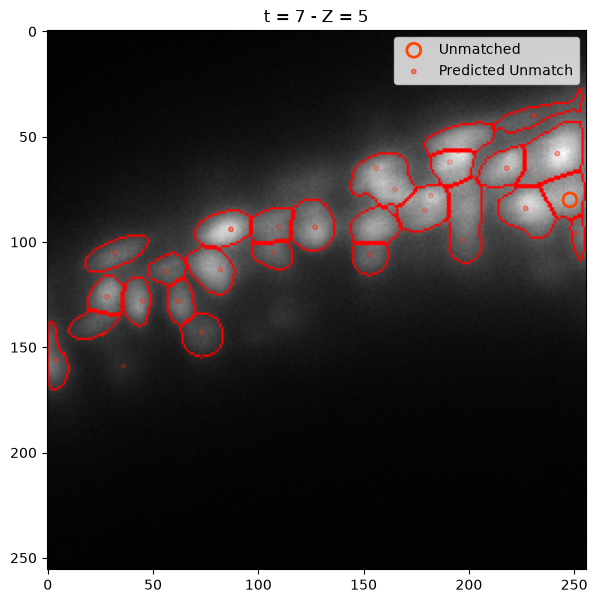

 12%|█▏        | 12/100 [00:57<07:02,  4.80s/it]

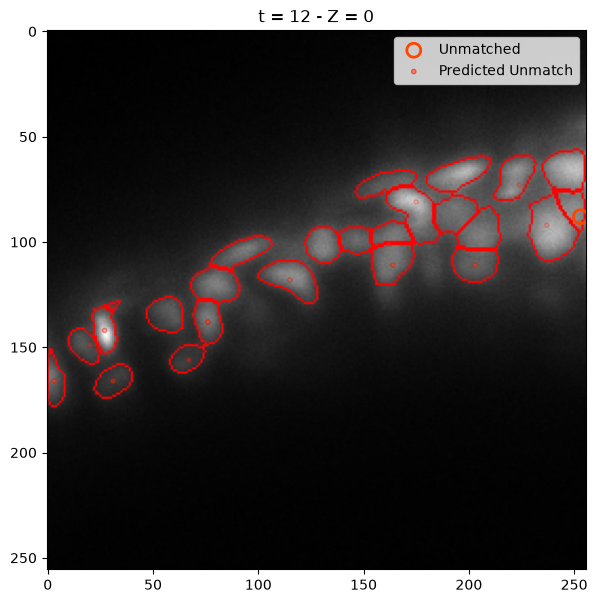

 13%|█▎        | 13/100 [01:02<07:02,  4.86s/it]

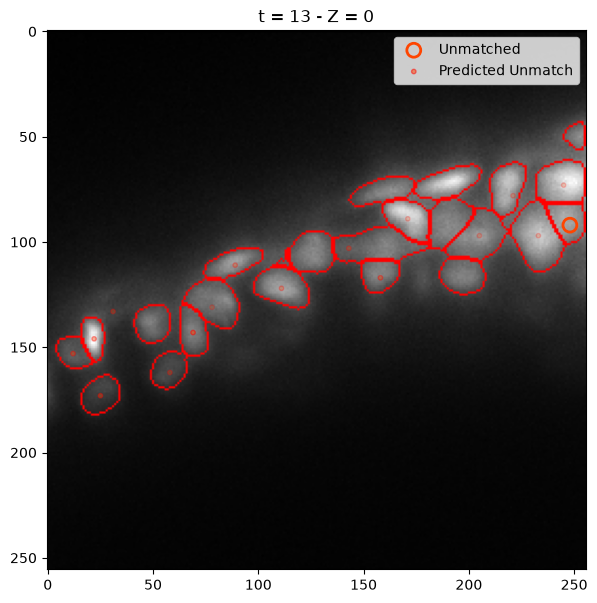

 17%|█▋        | 17/100 [01:21<06:43,  4.86s/it]

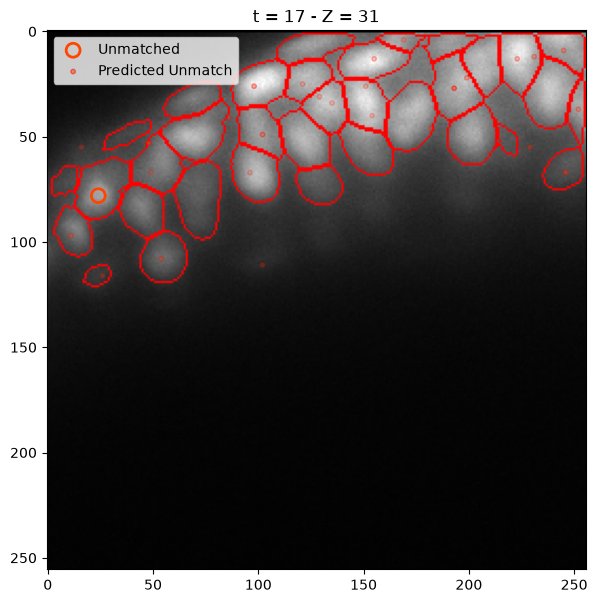

 18%|█▊        | 18/100 [01:26<06:36,  4.83s/it]

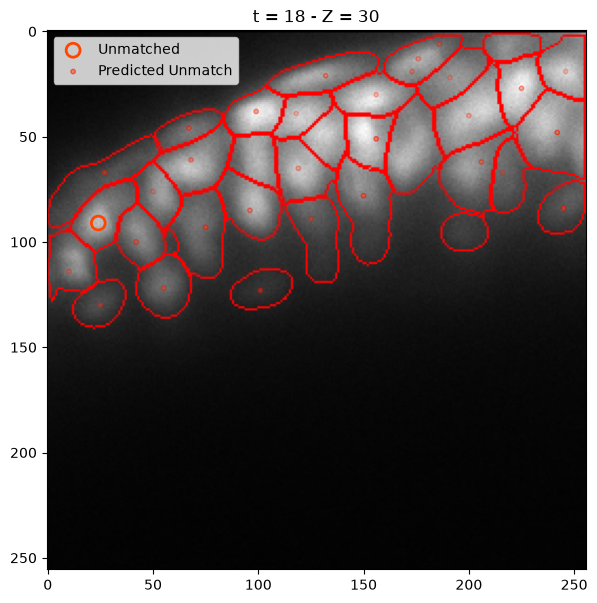

 26%|██▌       | 26/100 [02:09<06:09,  4.99s/it]


KeyboardInterrupt: 

In [29]:
predicted_nodes = {}
found = 0
total = 0

for t in tqdm(range(100), disable=VERBOSE):
    img = np.load(IMG_FOLDER + f"{sample_name}_{t}.npy")

    # Normalize image
    # img = img.astype(np.float32)
    # for z in range(img.shape[0]):    
    #     img[z] = np.clip(img[z], np.percentile(img[z], 1), np.percentile(img[z], 99))
    #     img[z] = (img[z] - img[z].min()) / (img[z].max() - img[z].min())
    # img = (np.clip(img, 0, 1) * 255).astype(np.uint8)

    gt = nodes[nodes["t"] == t][["z", "y", "x"]].values

    # Cellpose Segmentation
    masks, flows, styles = model.eval(
        img[..., None],
        batch_size=64,
        flow_threshold=flow_threshold,
        cellprob_threshold=cellprob_threshold,
        # normalize={"tile_norm_blocksize": tile_norm_blocksize},
    )

    # 3D Stitching
    masks_3d = stitch3D(masks, stitch_threshold=STITCH_THRESHOLD)

    ids = np.unique(masks_3d)
    seeds = ndimage.center_of_mass(masks_3d > 0, masks_3d, ids[ids > 0])
    seeds = np.round(np.asarray(seeds))

    masks_3d, seeds = merge_close_cells_v2(masks_3d, seeds, max_dist=MAX_DIST)

    # Small cells removal
    if MIN_SIZE:
        for i in range(1, masks_3d.max()):
            sz  = np.sum(masks_3d == i)
            if sz < MIN_SIZE:
                masks_3d[masks_3d == i] = 0

        ids = np.unique(masks_3d)
        ids = ids[ids > 0]
        seeds = ndimage.center_of_mass(masks_3d > 0, masks_3d, ids)
        seeds = np.round(np.asarray(seeds))

    predicted_nodes[t] = seeds

    # Eval nodes detection
    pairs, matched_gt, unmatched_gt  = match_frame_nodes(
        seeds,
        gt,
        t=t,
        scale=SCALE,
        max_distance=7,
    )
    found += len(pairs)
    total += len(gt)

    if VERBOSE:
        print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

    if PLOT and len(unmatched_gt):  
        tol = 3

        for i in np.sort(np.unique(unmatched_gt[:, 0])):
            plt.figure(figsize=(7, 7))
            plt.title(f"t = {t} - Z = {i}")

            plot_contours(img[i], masks_3d[i])
            # break
            scatter_plot_center_preds(seeds, matched_gt, unmatched_gt, frame=i, tol=tol)
            plt.show()
    
        # break


In [26]:
with open(OUTPUT_FOLDER + f"predicted_nodes_{sample_name}_3.json", "w") as f:
    json.dump({t: predicted_nodes[t].tolist() for t in predicted_nodes}, f)

## Graph

In [49]:
from utils.build_graph import build_graph_from_nodes
from utils.plot import plot_trajectory

from tracking_cellmot.metrics import evaluate, per_sample_metrics, node_recall, summarise

In [28]:
from utils.plot import (
    link_errors,
    error_report,
    plot_error_summary,
    plot_error_map,
    plot_error_neighbourhood,
    plot_trajectory_errors
)


### Edges

In [ ]:
# sample_name = "6bba_09961292"
sample_name = "44b6_0db75fae"

In [66]:
df = pd.read_csv(INPUT_FOLDER + f"metadata.csv")

In [67]:
predicted_nodes = json.load(open(OUTPUT_FOLDER + f"predicted_nodes_{sample_name}_3.json"))
predicted_nodes = {int(k): np.asarray(v) for k, v in predicted_nodes.items()}

In [68]:
gt_graph, _ = td.graph.IndexedRXGraph.from_geff(f"{str(TRAIN_DIR)}/{sample_name}.geff")
gt_nodes = gt_graph.node_attrs()
gt_edges = gt_graph.edge_attrs()

In [69]:
graph = build_graph_from_nodes(predicted_nodes, max_distance=7.0)

In [75]:
res = evaluate(graph, gt_graph, scale=SCALE)

node_recall_ = node_recall(graph, gt_graph)
print(f"- Node recall: {node_recall_:.3f}")

n_total = df[df['sample_name'] == sample_name]["estimated_number_of_nodes"].values[0]
print(f"- Estimated number of nodes: {n_total}")

metrics = per_sample_metrics(res, n_total, node_recall_)
metrics = summarise([metrics])

for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")

- Node recall: 0.981
- Estimated number of nodes: 25755
- edge_tp: 47
- edge_fp: 4
- edge_fn: 3
- edge_jaccard: 0.870
- adj_edge_jaccard: 0.874
- division_jaccard: nan
- score: 0.874


### PP

In [76]:
ILD_EDGE_W = -1.0 
ILP_APPEARANCE_W = 0.1 
ILP_DISAPPEARANCE_W = 0.1 
ILP_DIVISION_W = 1.0

In [77]:
# %%time
# solver = td.solvers.ILPSolver(
#     edge_weight=ILD_EDGE_W * td.EdgeAttr("edge_prob"),
#     appearance_weight=ILP_APPEARANCE_W,
#     disappearance_weight=ILP_DISAPPEARANCE_W,
#     division_weight=ILP_DIVISION_W,
# )

# graph_ilp = solver.solve(graph).detach()

In [78]:
# res = evaluate(graph_ilp, gt_graph, scale=SCALE)

# node_recall_ = node_recall(graph_ilp, gt_graph)
# print(f"- Node recall: {node_recall_:.3f}")

# metrics = per_sample_metrics(res, n_total, node_recall_)
# metrics = summarise([metrics])

# for k in ["edge_tp", "edge_fp", "edge_fn"]:
#     print(f"- {k}: {metrics[k]:.0f}")
# for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
#     print(f"- {k}: {metrics[k]:.3f}")

In [79]:
from tracking.pp_public import postprocess_graph
from tracking.post_process import build_graph

In [80]:
%%time
nodes_pp, edges_pp, filter_stats = postprocess_graph(graph, dataset=sample_name)

CPU times: user 10.2 s, sys: 29.8 ms, total: 10.3 s
Wall time: 10.2 s


In [81]:
id_mapping = {n['node_id']: i for i, n in enumerate(nodes_pp)}
nodes_pp = [[n['t'], n['z'], n['y'], n['x']] for n in nodes_pp]
nodes_pp = np.array(nodes_pp)

edges_pp_ = [(id_mapping[e['source_id']], id_mapping[e['target_id']], e['edge_prob'], e['distance_um']) for e in edges_pp]

In [82]:
print(f'Post processed graph: {len(nodes_pp)} nodes (estimated {n_total}) & {len(edges_pp_)} edges')

Post processed graph: 25324 nodes (estimated 25755) & 24030 edges


In [83]:
graph_pp = build_graph(nodes_pp, edges_pp_)

In [84]:
res = evaluate(graph_pp, gt_graph, scale=SCALE)

node_recall_ = node_recall(graph_pp, gt_graph)
print(f"- Node recall: {node_recall_:.3f}")

n_total = df[df['sample_name'] == sample_name]["estimated_number_of_nodes"].values[0]
print(f"- Estimated number of nodes: {n_total}")

metrics = per_sample_metrics(res, n_total, node_recall_)
metrics = summarise([metrics])

for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")

- Node recall: 0.962
- Estimated number of nodes: 25755
- edge_tp: 44
- edge_fp: 6
- edge_fn: 6
- edge_jaccard: 0.786
- adj_edge_jaccard: 0.787
- division_jaccard: nan
- score: 0.787


### Plots

In [ ]:
gt_nodes.filter(gt_nodes["t"] == 0)["node_id"].to_numpy()

In [ ]:
node_ids = plot_trajectory(gt_graph, root=1000002)     # a specific starting cell

In [ ]:
node_ids = plot_trajectory_errors(graph, gt_graph, root=1000002)     # a specific starting cell

In [ ]:

# One row per ground-truth edge, saying what we did with it. Needs the graph to
# have been matched, which the evaluate call above did.
errors = link_errors(graph, gt_graph, scale=SCALE)
display(error_report(errors))

plot_error_summary(errors)

In [ ]:
# The frame that went worst, then the single link we lost by the widest margin.
# Swap the query for kind == 'no link' to look at the parents we left childless.
worst_frame = errors[errors["kind"] != "correct"]["t"].value_counts().idxmax()
worst_link = errors.query("kind == 'wrong partner'").sort_values("margin").iloc[0]

plt.figure(figsize=(9, 9))
plot_error_map(graph, errors, t=worst_frame)

plot_error_neighbourhood(graph, worst_link, radius=10.0);

Done !